# PXR dose-response: raw plate data → 4PL fit → potency + 2D structures

**Goal.** Take raw luciferase plate data from the OpenADMET/Octant PXR HTChem blog-post repository (experiment **OPA_PXR-046**: GAL4-PXR reporter cells, 9-point titration, 5 nM – 50 µM), extract 20 compounds, fit a four-parameter logistic (4PL) curve to each, and plot every curve next to its 2D structure on identical axes.

| Step | What happens | Output |
|---|---|---|
| 1–3 | Download raw wells, structures and the authors' fits | `data/source_046_stats/`, `data/source_046_cdd/` |
| 4–6 | Select 20 compounds, save their raw wells as TSV, read it back | `data/pxr_046_raw_20cpds.tsv`, `data/pxr_046_structures_20cpds.tsv` |
| 7–8 | Fit a 4PL curve per compound | `data/pxr_046_fit_results_20cpds.tsv` |
| 9 | Plot curves + structures | `figures/pxr_046_dose_response_20cpds.png` / `.pdf` |
| 10 | Cross-check against the authors' published fits | inline figure |

**Units.**
- Concentration: µM (the raw file stores mol/L in `chem_m`).
- Response: luciferase signal normalised per plate, dimensionless. ≈ 0 at the negative-control (vehicle) level and 1 = the positive-control response (the dataset README states Emax is "normalized to the positive control").
- Potency: EC₅₀ in µM and pEC₅₀ = −log₁₀(EC₅₀ / M); higher pEC₅₀ = more potent.

## 1. Setup
Imports, source URLs, output paths and the plotting style (colours from the dataviz reference palette: blue = data, orange = fit, neutral ink for all text).

In [1]:
import io
from pathlib import Path
import urllib.parse
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.gridspec import GridSpecFromSubplotSpec
from matplotlib.lines import Line2D
from PIL import Image
from rdkit import Chem
from rdkit.Chem.Draw import rdMolDraw2D
from scipy import optimize, stats

# --- sources (OpenADMET/octant-pxr-htchem-blogpost, data/raw/drc/htchem-libraries/)
REPO = ("https://raw.githubusercontent.com/OpenADMET/octant-pxr-htchem-blogpost/main/"
        "data/raw/drc/htchem-libraries/")
RAW_URL = REPO + "OPA_PXR-046_55547_processed-data_OCNT-0002416/stats.tsv"   # raw per-well data
CDD_URL = REPO + urllib.parse.quote(                                          # SMILES + authors' fits
    "CDD CSV Export - 2026-04-22 Run of luci_drc_PXR OCNT-0002416 Mini-Am Library.csv")

# --- outputs
DATA, FIGS = Path("data"), Path("figures")
RAW_TSV = DATA / "pxr_046_raw_20cpds.tsv"
STRUCT_TSV = DATA / "pxr_046_structures_20cpds.tsv"
FIT_TSV = DATA / "pxr_046_fit_results_20cpds.tsv"
N_COMPOUNDS = 20

# --- style: dataviz reference palette (blue = measured data, orange = fit)
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e1e0dc"
plt.rcParams.update({
    "font.size": 13, "axes.labelsize": 13, "xtick.labelsize": 12, "ytick.labelsize": 12,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 1.0, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
})

## 2. Load the raw plate data
`stats.tsv` has one row per well: plate position, compound, concentration (`chem_m`, mol/L), raw luminescence (`luci`, RLU) and `luci_norm` (the same signal rescaled per plate, so plates are comparable). Rows with `compound_class == "Library"` are compound wells; the rest are negative-control wells.

Each source file is downloaded once into its own folder under `data/`.

In [2]:
def download(url, folder, filename):
    # Fetch `url` once into data/<folder>/<filename>; later runs reuse the local copy.
    dest = DATA / folder / filename
    if not dest.exists():
        dest.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(url, dest)
    return dest


raw_all = pd.read_csv(
    download(RAW_URL, "source_046_stats", "stats.tsv"),
    sep="\t", na_values=["NA"], keep_default_na=False, dtype={"batch_name": str},
)
raw = raw_all[raw_all.compound_class == "Library"].copy()
raw["conc_uM"] = raw.chem_m * 1e6          # mol/L -> µM

print(raw_all.compound_class.value_counts().to_string(), "\n")
print(f"{raw.molecule_name.nunique()} library compounds, "
      f"{raw.conc_uM.min():.4f} – {raw.conc_uM.max():.1f} µM")
raw.head(3)

compound_class
Library              2041
Negative Control      228
Core_only Control     108 

228 library compounds, 0.0052 – 50.4 µM


,plate,channel,row,col,molecule_name,batch_name,chem_id,chem_m,compound_class,luci,corrected,luci_norm,efdr,cell_line,conc_uM
1,Plate01,Luminescence,B,10,OCNT-2432809,ZZ-002,OCNT-2432809||NA|NA|ZZ-002,5.245524e-09,Library,133574,NaN,0.148484,NaN,c6385,0.005246
2,Plate01,Luminescence,B,12,OCNT-2432603,ZZ-002,OCNT-2432603||NA|NA|ZZ-002,5.245524e-09,Library,129592,NaN,0.136355,NaN,c6385,0.005246
3,Plate01,Luminescence,B,15,OCNT-2432972,ZZ-002,OCNT-2432972||NA|NA|ZZ-002,5.245524e-09,Library,133203,NaN,0.147354,NaN,c6385,0.005246


## 3. Load structures and the authors' reference fits
The CDD export (processed, one row per compound) is used for two things only: the **SMILES** for the 2D drawings and the authors' own EC₅₀ / QC flags (used to choose compounds in step 4 and to cross-check my fits in step 10). It contains no per-well data, so none of it enters the curve fitting.

In [3]:
cdd = pd.read_csv(download(CDD_URL, "source_046_cdd", "cdd.csv"), low_memory=False)
ref = pd.DataFrame({
    "molecule_name": cdd["Molecule Name"],
    "smiles": cdd["Structure (CXSMILES)"],
    "author_pEC50": -cdd["ec50_estimate (log10([M]))"],   # log10(EC50 / M) -> pEC50
    "activity": cdd["activity_status"],                   # YES = shows activation
    "rollover": cdd["rollover_status"],                   # YES = signal falls at high conc.
    "qc": cdd["qc_flag"],
})
ref.head(3)

,molecule_name,smiles,author_pEC50,activity,rollover,qc
0,OCNT-0002416,COC(C)(C(=O)O)C1=CC=CC=C1,2.73,YES,NO,PASS
1,OCNT-2432809,COC(C)(C(=O)NC1CCC2=NC(C3=CC=CC=C3)=NC=C2C1)C1...,3.79,YES,NO,PASS
2,OCNT-2432603,CCOC=CC(O)(CNC(=O)C(C)(OC)C1=CC=CC=C1)C(F)(F)F,5.52,YES,NO,PASS


## 4. Select 20 compounds
A fixed, reproducible rule, so the choice is not hand-picked:

1. **Eligible:** complete 9-point series; authors' flags `activity = YES`, `rollover = NO`, `qc = PASS`; maximum normalised response ≥ 0.5 (a clear activator); and **no rollover in the data itself**: the response at the top concentration is ≥ 80 % of the maximum observed.
2. **Spread across potency:** sort eligible compounds by the authors' pEC₅₀ and take 20 evenly spaced ranks, from most to least potent.

Rollover compounds are excluded because a 4PL curve cannot describe a signal that rises and then falls. The data check is needed on top of the authors' flag: some compounds the flag passes still collapse at 50 µM.

In [4]:
by_conc = raw.sort_values("conc_uM").groupby("molecule_name")
per_cpd = pd.DataFrame({
    "n_points": by_conc.size(),
    "max_response": by_conc.luci_norm.max(),
    "top_conc_response": by_conc.luci_norm.last(),     # response at the highest concentration
})
per_cpd["top_over_max"] = per_cpd.top_conc_response / per_cpd.max_response
candidates = ref.merge(per_cpd, left_on="molecule_name", right_index=True)

eligible = candidates[
    (candidates.n_points == 9) & (candidates.activity == "YES")
    & (candidates.rollover == "NO") & (candidates.qc == "PASS")
    & (candidates.max_response >= 0.5) & (candidates.top_over_max >= 0.8)
].sort_values("author_pEC50", ascending=False)

rank_idx = np.linspace(0, len(eligible) - 1, N_COMPOUNDS).round().astype(int)
assert len(set(rank_idx)) == N_COMPOUNDS, "not enough eligible compounds"
selected = eligible.iloc[rank_idx].reset_index(drop=True)

print(f"{len(candidates)} compounds -> {len(eligible)} eligible -> {len(selected)} selected")
selected[["molecule_name", "author_pEC50", "max_response", "smiles"]].round(2)

228 compounds -> 79 eligible -> 20 selected


,molecule_name,author_pEC50,max_response,smiles
0,OCNT-2433106,5.76,0.72,COC(C)(C(=O)NCCCN1N=C2CCCC2=C1C(F)(F)F)C1=CC=C...
1,OCNT-2433636,5.66,0.53,COC(C)(C(=O)N(CC1=CC=C(C(N)=O)C=C1F)C1CC1)C1=C...
2,OCNT-2433138,5.61,0.70,COC(C)(C(=O)NCCOC1=NC2=CC=CC=C2S1)C1=CC=CC=C1
3,OCNT-2432896,5.54,1.45,COC(C)(C(=O)NC(CC(C)C)C1=CC=CC(C#N)=C1)C1=CC=C...
4,OCNT-2432526,5.50,0.73,C=C1C(NC(=O)C(C)(OC)C2=CC=CC=C2)C[C@H]2C[C@@H]...
5,OCNT-2433783,5.42,0.91,COC(C)(C(=O)N1CCC2=CC(O)=CC=C2C1C(C)(C)C)C1=CC...
6,OCNT-2432693,5.39,1.18,COC(C)(C(=O)N[C@H]1CC(=O)N(C)[C@@H]1C1=CC=C(Cl...
7,OCNT-2433565,5.36,0.72,COC(C)(C(=O)N1C[C@H](C#N)[C@@H](C2=CC=CC=C2)C1...
8,OCNT-2433726,5.32,1.71,CCN(CC)C(=O)C1(CC)CCCN(C(=O)C(C)(OC)C2=CC=CC=C...
9,OCNT-2432931,5.26,1.12,COC(C)(C(=O)NC(C)C1CC2CCC1CC2)C1=CC=CC=C1


## 5. Extract the raw wells and save as TSV
Keep only the 20 selected compounds' wells and the columns needed for fitting. `luci` (raw RLU) is kept next to `luci_norm` so the raw values stay available. Structures go in a separate small TSV.

In [5]:
DATA.mkdir(exist_ok=True)
keep_cols = ["plate", "row", "col", "molecule_name", "batch_name",
             "chem_m", "conc_uM", "luci", "luci_norm"]
extract = (raw[raw.molecule_name.isin(selected.molecule_name)][keep_cols]
           .sort_values(["molecule_name", "conc_uM"]))

extract.to_csv(RAW_TSV, sep="\t", index=False)
selected[["molecule_name", "smiles"]].to_csv(STRUCT_TSV, sep="\t", index=False)
print(f"saved {len(extract)} wells for {extract.molecule_name.nunique()} compounds -> {RAW_TSV}")

saved 180 wells for 20 compounds -> data/pxr_046_raw_20cpds.tsv


## 6. Read the TSV back
From here on only the saved files are used, so the analysis is reproducible from the TSVs alone. The assertions confirm nothing was lost in the round trip.

In [6]:
wells = pd.read_csv(RAW_TSV, sep="\t", keep_default_na=False, dtype={"batch_name": str})
structures = pd.read_csv(STRUCT_TSV, sep="\t")

assert len(wells) == len(extract) and wells.molecule_name.nunique() == N_COMPOUNDS
assert np.allclose(wells.luci_norm.values, extract.luci_norm.values)
print(wells.groupby("molecule_name").size().value_counts().rename("compounds per n_points").to_string())
wells.head(9)

9    20


,plate,row,col,molecule_name,batch_name,chem_m,conc_uM,luci,luci_norm
0,Plate01,M,27,OCNT-2432526,ZZ-002,5.245524e-09,0.005246,77257,-0.023064
1,Plate01,N,27,OCNT-2432526,ZZ-002,1.573657e-08,0.015737,76516,-0.025321
2,Plate01,O,27,OCNT-2432526,ZZ-002,5.245524e-08,0.052455,70982,-0.042178
3,Plate01,P,27,OCNT-2432526,ZZ-002,1.273232e-07,0.127323,88782,0.012043
4,Plate01,Q,27,OCNT-2432526,ZZ-002,5.092927e-07,0.509293,108980,0.073568
5,Plate01,R,27,OCNT-2432526,ZZ-002,1.527878e-06,1.527878,145815,0.185772
6,Plate01,S,27,OCNT-2432526,ZZ-002,4.201665e-06,4.201665,241884,0.478410
7,Plate01,T,27,OCNT-2432526,ZZ-002,1.680666e-05,16.806660,324467,0.729968
8,Plate01,U,27,OCNT-2432526,ZZ-002,5.041998e-05,50.419980,318335,0.711289


## 7. Four-parameter logistic (4PL) model
$$y = \text{bottom} + \frac{\text{top}-\text{bottom}}{1 + 10^{(\log_{10}\text{EC}_{50}-\log_{10}c)\cdot h}}$$

Fitted in log₁₀(µM) space with bounded least squares (`scipy.optimize.curve_fit`, trust-region) and five different starting EC₅₀ guesses; the lowest-error fit is kept.
- **Bounds:** bottom −0.2…0.2, top 0…3, Hill slope 0.3…5, log₁₀ EC₅₀ within one decade of the tested range.
- **Uncertainty:** standard error from the fit covariance, 95 % CI = SE × t(0.975, n − 4).
- **Quality label:** `full curve` (fitted plateau reached at top concentration), `partial curve` (top is extrapolated) or `EC50 above top conc.` (potency is only a lower-bound estimate).

In [7]:
def four_pl(log_conc, bottom, top, log_ec50, hill):
    # 4PL response at log10(concentration in µM).
    return bottom + (top - bottom) / (1.0 + 10.0 ** ((log_ec50 - log_conc) * hill))


def fit_4pl(conc_uM, response):
    # Fit one curve; returns parameters, pEC50 and its standard error / 95% CI half-width.
    x, y = np.log10(conc_uM), np.asarray(response, float)
    lower = [-0.2, 0.0, x.min() - 1, 0.3]
    upper = [0.2, 3.0, x.max() + 1, 5.0]
    best = None
    for start in np.linspace(x.min(), x.max(), 5):          # guard against local minima
        p0 = [np.clip(y.min(), -0.19, 0.19), np.clip(y.max(), 0.05, 2.9), start, 1.0]
        try:
            popt, pcov = optimize.curve_fit(four_pl, x, y, p0=p0, bounds=(lower, upper), max_nfev=20000)
        except RuntimeError:
            continue
        sse = float(np.sum((y - four_pl(x, *popt)) ** 2))
        if best is None or sse < best[0]:
            best = (sse, popt, pcov)
    sse, (bottom, top, log_ec50, hill), pcov = best

    with np.errstate(invalid="ignore"):
        se = np.sqrt(np.diag(pcov))[2]                       # SE of log10(EC50)
    se = se if np.isfinite(se) else np.nan
    ci95 = stats.t.ppf(0.975, len(y) - 4) * se
    return dict(bottom=bottom, top=top, hill=hill, log_ec50=log_ec50,
                ec50_uM=10 ** log_ec50, pEC50=6.0 - log_ec50,   # log10(µM) -> -log10(M)
                pEC50_se=se, pEC50_ci95=ci95, rmse=np.sqrt(sse / len(y)))


def fit_quality(fit, conc_uM):
    # Label how well the tested concentration range constrains the fit.
    if fit["ec50_uM"] > conc_uM.max():
        return "EC50 above top conc."
    if fit["ec50_uM"] < conc_uM.min():
        return "EC50 below lowest conc."
    y_top = four_pl(np.log10(conc_uM.max()), fit["bottom"], fit["top"], fit["log_ec50"], fit["hill"])
    return "full curve" if y_top >= fit["bottom"] + 0.9 * (fit["top"] - fit["bottom"]) else "partial curve"

## 8. Fit all 20 compounds
One fit per compound using the normalised response. The table is sorted from most to least potent and also shows the authors' pEC₅₀ (`author_pEC50`) and the difference (`delta_pEC50`); results are saved to TSV with full precision.

In [8]:
rows = []
for name, g in wells.groupby("molecule_name"):
    g = g.sort_values("conc_uM")
    fit = fit_4pl(g.conc_uM.values, g.luci_norm.values)
    rows.append({"molecule_name": name, "n_points": len(g), **fit,
                 "fit_quality": fit_quality(fit, g.conc_uM.values)})

fits = (pd.DataFrame(rows)
        .merge(structures, on="molecule_name")
        .merge(ref[["molecule_name", "author_pEC50"]], on="molecule_name")
        .sort_values("pEC50", ascending=False).reset_index(drop=True))
fits["delta_pEC50"] = fits.pEC50 - fits.author_pEC50
fits.to_csv(FIT_TSV, sep="\t", index=False)

fits[["molecule_name", "n_points", "ec50_uM", "pEC50", "pEC50_ci95", "hill", "top",
      "fit_quality", "author_pEC50", "delta_pEC50"]].round(2)

,molecule_name,n_points,ec50_uM,pEC50,pEC50_ci95,hill,top,fit_quality,author_pEC50,delta_pEC50
0,OCNT-2433106,9,1.62,5.79,0.11,1.72,0.72,full curve,5.76,0.03
1,OCNT-2433636,9,2.02,5.69,0.12,1.76,0.53,full curve,5.66,0.03
2,OCNT-2433138,9,2.29,5.64,0.11,1.92,0.67,full curve,5.61,0.03
3,OCNT-2432526,9,2.78,5.56,0.13,1.51,0.75,full curve,5.50,0.06
4,OCNT-2432896,9,2.79,5.55,0.08,1.70,1.45,full curve,5.54,0.01
5,OCNT-2433783,9,3.56,5.45,0.11,1.31,0.93,full curve,5.42,0.03
6,OCNT-2433565,9,4.38,5.36,0.08,1.38,0.74,full curve,5.36,-0.00
7,OCNT-2432693,9,4.93,5.31,0.12,1.03,1.27,full curve,5.39,-0.08
8,OCNT-2432931,9,5.98,5.22,0.08,1.63,1.14,full curve,5.26,-0.04
9,OCNT-2432891,9,6.43,5.19,0.36,1.80,0.65,full curve,5.22,-0.03


## 9. Plot: curve + 2D structure for each compound
Each panel stacks the RDKit drawing above the dose-response plot. **All 20 plots share the same x-limits (log µM) and y-limits**, set once from the data of all 20 compounds. Dots are the measured wells (one per concentration), the orange line is the 4PL fit over the tested range, and the dotted vertical line marks the fitted EC₅₀. Panels run from most to least potent, left to right and top to bottom.

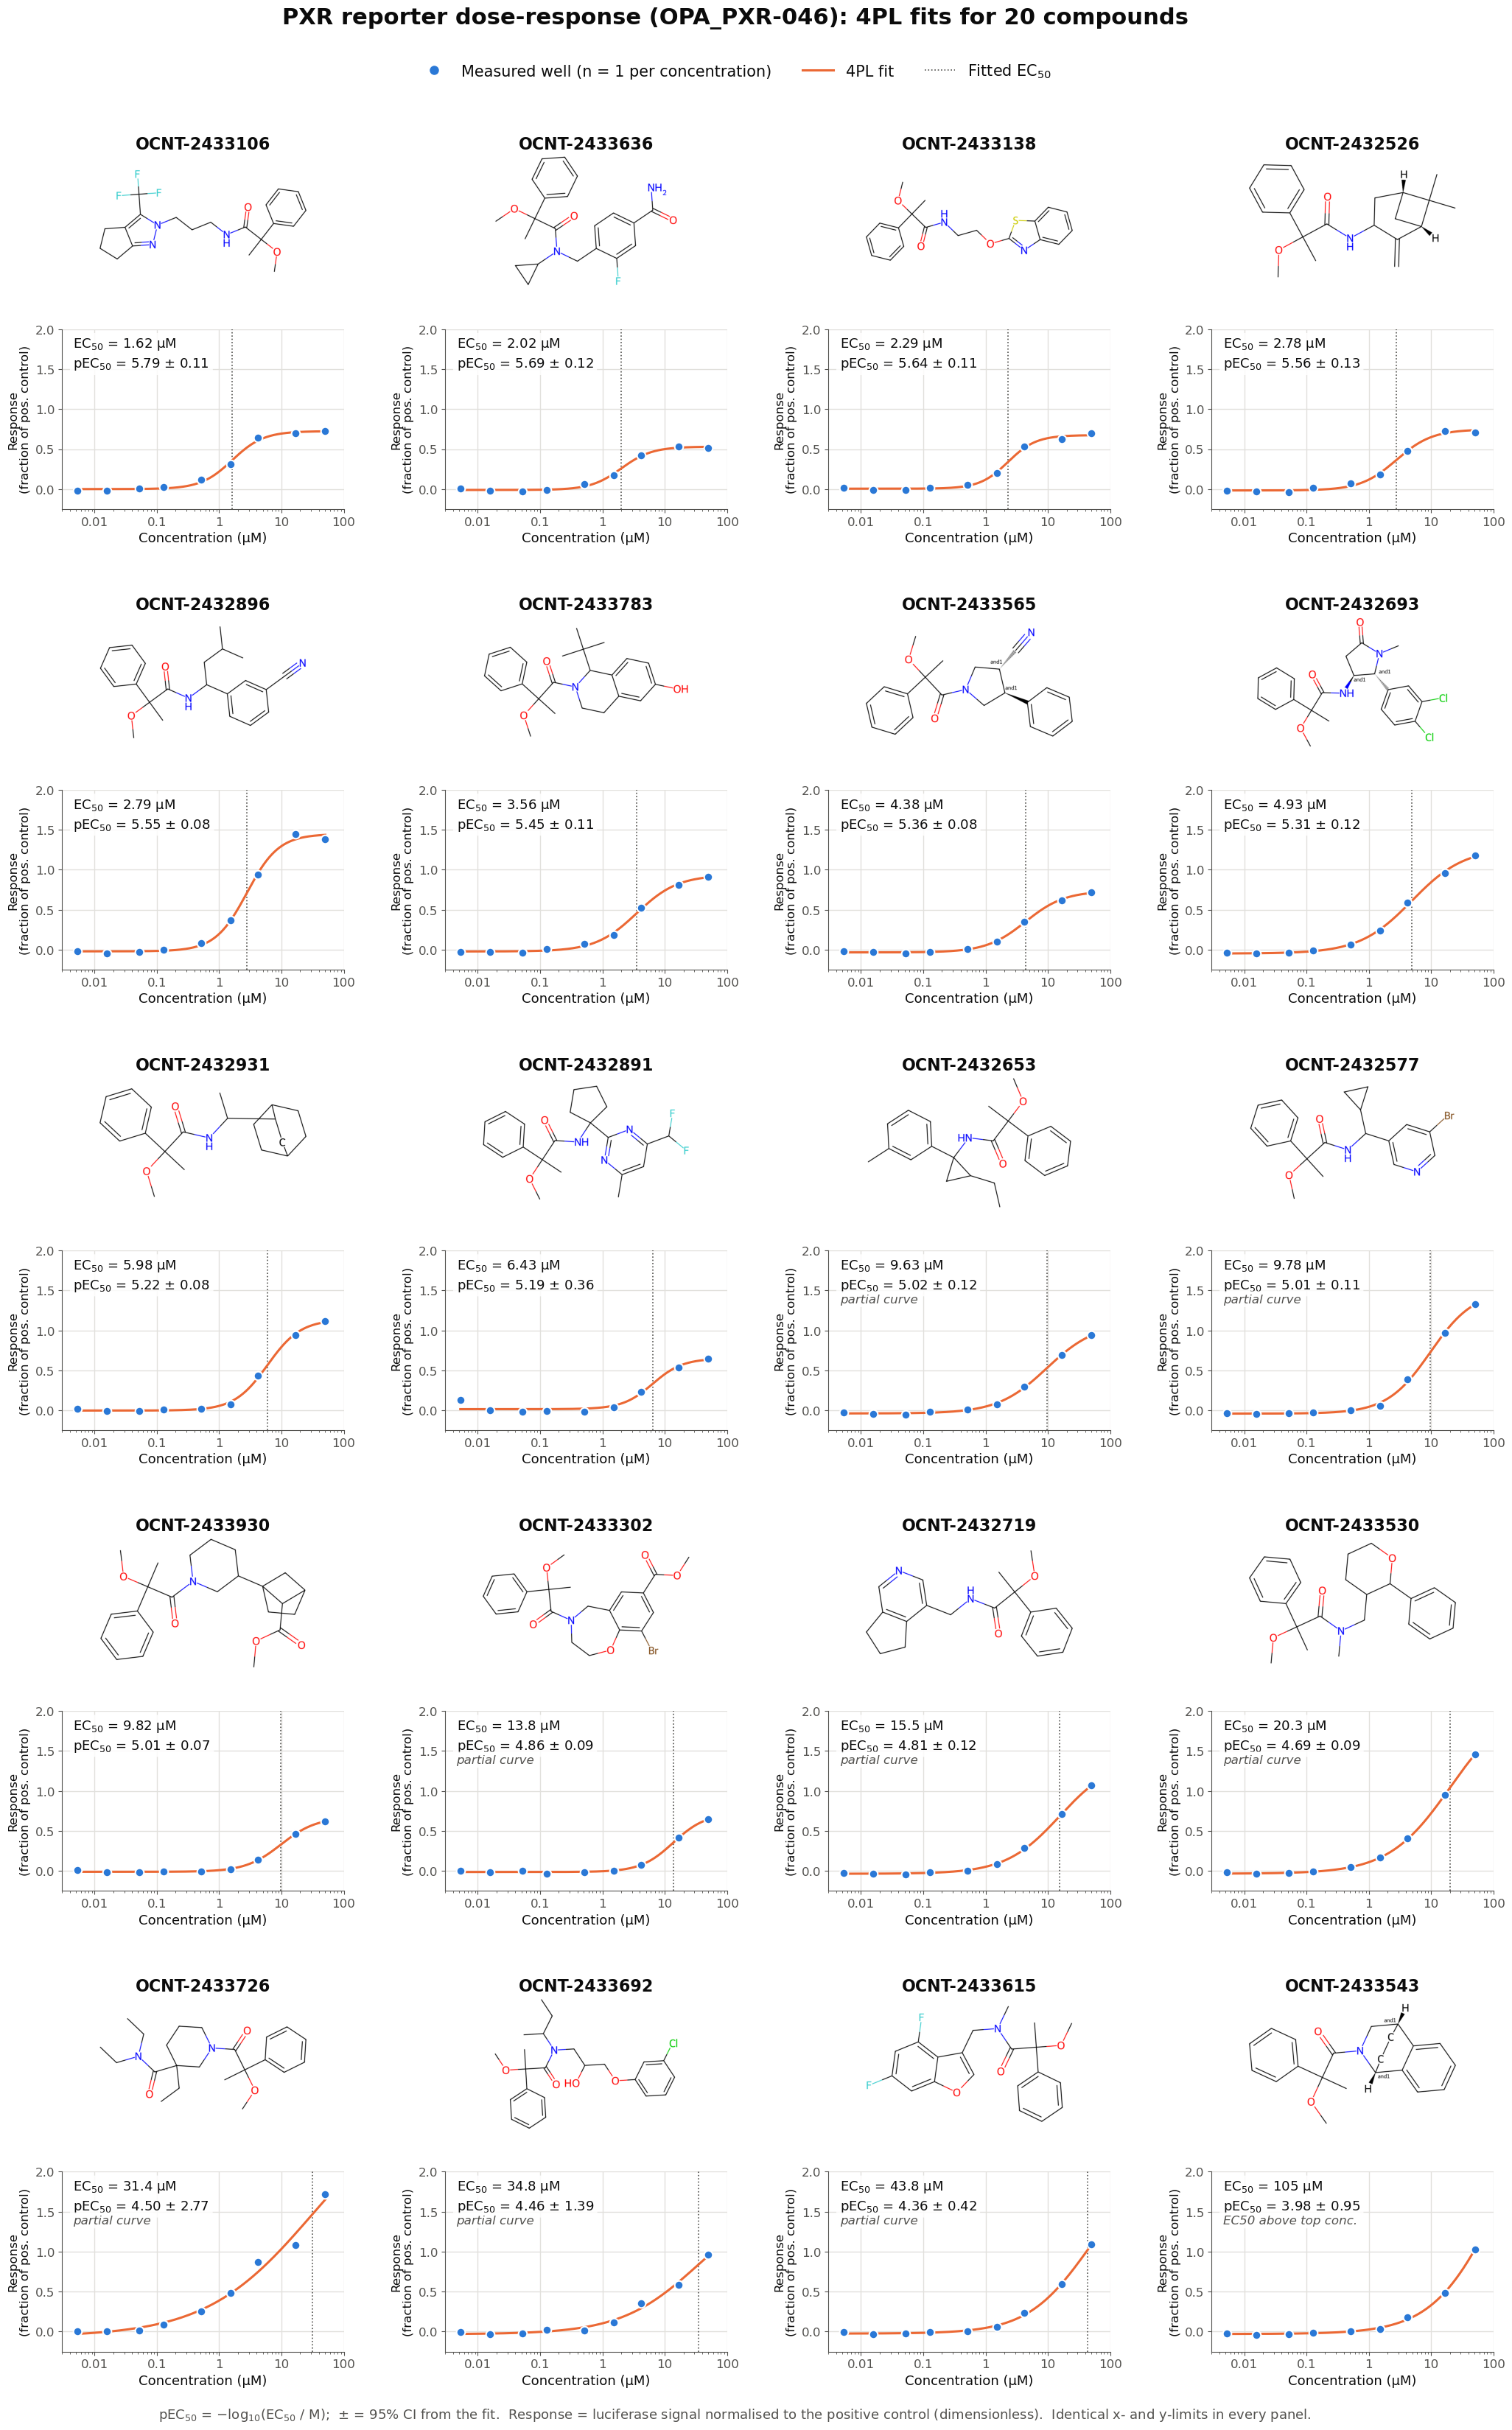

In [9]:
# --- shared axis limits for every panel
XLIM = (3e-3, 1e2)                                   # µM; the data span 0.005 – 50 µM
y_all = wells.luci_norm
YLIM = (np.floor((y_all.min() - 0.03) / 0.25) * 0.25,  # round outwards to 0.25 steps
        np.ceil((y_all.max() + 0.10) / 0.25) * 0.25)
YTICKS = np.arange(np.ceil(YLIM[0] / 0.5) * 0.5, YLIM[1] + 1e-9, 0.5)


def draw_structure(ax, smiles, title):
    # RDKit 2D depiction (large atom labels, thick bonds) with the compound ID as a bold heading.
    mol = Chem.MolFromSmiles(smiles)
    assert mol is not None, f"bad SMILES for {title}"
    drawer = rdMolDraw2D.MolDraw2DCairo(800, 500)
    opts = drawer.drawOptions()
    opts.baseFontSize, opts.bondLineWidth, opts.padding = 0.9, 3, 0.02
    drawer.DrawMolecule(mol)
    drawer.FinishDrawing()
    ax.imshow(Image.open(io.BytesIO(drawer.GetDrawingText())))
    ax.set_axis_off()
    ax.set_title(title, fontsize=16, fontweight="bold", color=INK, pad=6)


def draw_curve(ax, g, fit):
    # Measured wells, 4PL fit, fitted EC50 marker and potency annotation on shared axes.
    c, y = g.conc_uM.values, g.luci_norm.values
    xs = np.logspace(np.log10(c.min()), np.log10(c.max()), 200)
    ax.plot(xs, four_pl(np.log10(xs), fit.bottom, fit.top, fit.log_ec50, fit.hill),
            color=ORANGE, lw=2.2, zorder=2)
    if XLIM[0] < fit.ec50_uM < XLIM[1]:
        ax.axvline(fit.ec50_uM, color=MUTED, lw=1.2, ls=":", zorder=1)
    ax.scatter(c, y, s=70, color=BLUE, edgecolor="white", linewidth=1.5, zorder=3)

    ci = f"± {fit.pEC50_ci95:.2f}" if np.isfinite(fit.pEC50_ci95) else "(CI n/a)"
    ax.text(0.04, 0.96, f"EC$_{{50}}$ = {fit.ec50_uM:.3g} µM\npEC$_{{50}}$ = {fit.pEC50:.2f} {ci}",
            transform=ax.transAxes, va="top", ha="left", fontsize=13, linespacing=1.4,
            bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="none", alpha=0.85))
    if fit.fit_quality != "full curve":      # quality tag sits under the potency box (clear of the curve)
        ax.text(0.04, 0.76, fit.fit_quality, transform=ax.transAxes, va="top", ha="left",
                fontsize=12, style="italic", color=MUTED,
                bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.85))

    ax.set_xscale("log")
    ax.set_xlim(*XLIM); ax.set_ylim(*YLIM)
    ax.set_xticks([0.01, 0.1, 1, 10, 100])
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
    ax.xaxis.set_minor_formatter(plt.NullFormatter())
    ax.set_yticks(YTICKS)
    ax.set_xlabel("Concentration (µM)")
    ax.set_ylabel("Response\n(fraction of pos. control)", fontsize=12)


n_cols = 4
n_rows = int(np.ceil(len(fits) / n_cols))
fig = plt.figure(figsize=(21, 6.7 * n_rows), facecolor="white")
outer = fig.add_gridspec(n_rows, n_cols, hspace=0.30, wspace=0.36,
                         left=0.065, right=0.99, top=0.925, bottom=0.035)

for i, fit in fits.iterrows():
    inner = GridSpecFromSubplotSpec(2, 1, subplot_spec=outer[i // n_cols, i % n_cols],
                                    height_ratios=[1.3, 1.75], hspace=0.26)
    draw_structure(fig.add_subplot(inner[0]), fit.smiles, fit.molecule_name)
    draw_curve(fig.add_subplot(inner[1]), wells[wells.molecule_name == fit.molecule_name], fit)

fig.suptitle("PXR reporter dose-response (OPA_PXR-046): 4PL fits for 20 compounds",
             fontsize=22, fontweight="bold", y=0.985)
fig.legend(handles=[
    Line2D([], [], marker="o", ls="", color=BLUE, markeredgecolor="white", markersize=10, label="Measured well (n = 1 per concentration)"),
    Line2D([], [], color=ORANGE, lw=2.2, label="4PL fit"),
    Line2D([], [], color=MUTED, lw=1.2, ls=":", label="Fitted EC$_{50}$"),
], loc="upper center", bbox_to_anchor=(0.5, 0.968), ncol=3, frameon=False, fontsize=15)
fig.text(0.5, 0.008, "pEC$_{50}$ = −log$_{10}$(EC$_{50}$ / M);  ± = 95% CI from the fit.  "
         "Response = luciferase signal normalised to the positive control (dimensionless).  "
         "Identical x- and y-limits in every panel.",
         ha="center", fontsize=13, color=MUTED)

FIGS.mkdir(exist_ok=True)
for ext in ("png", "pdf"):
    fig.savefig(FIGS / f"pxr_046_dose_response_20cpds.{ext}", dpi=150, facecolor="white")
plt.show()

## 10. Cross-check against the authors' published fits
The authors' EC₅₀ values come from their own pipeline on the same wells. Points near the dashed identity line mean my 4PL fit agrees with theirs; large offsets usually mark partial curves, where EC₅₀ depends on the extrapolated plateau.

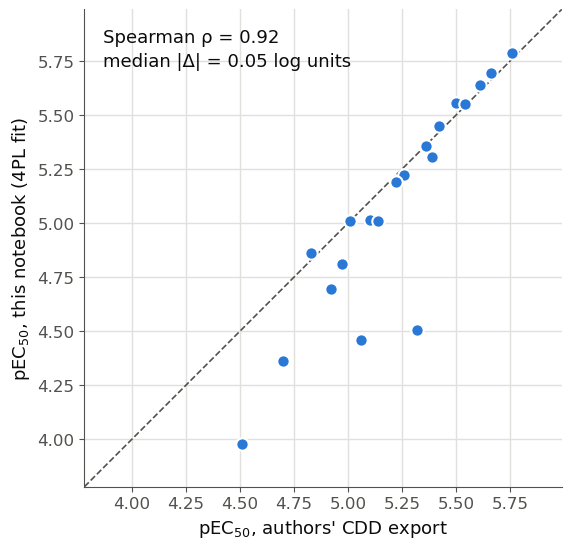

In [10]:
fig2, ax = plt.subplots(figsize=(6.5, 6.2), facecolor="white")
lim = (fits[["pEC50", "author_pEC50"]].min().min() - 0.2, fits[["pEC50", "author_pEC50"]].max().max() + 0.2)
ax.plot(lim, lim, color=MUTED, lw=1.2, ls="--", zorder=1)
ax.scatter(fits.author_pEC50, fits.pEC50, s=80, color=BLUE, edgecolor="white", linewidth=1.5, zorder=3)
ax.set_xlim(*lim); ax.set_ylim(*lim); ax.set_aspect("equal")
ax.set_xlabel("pEC$_{50}$, authors' CDD export")
ax.set_ylabel("pEC$_{50}$, this notebook (4PL fit)")

rho = stats.spearmanr(fits.pEC50, fits.author_pEC50).statistic
ax.text(0.04, 0.96, f"Spearman ρ = {rho:.2f}\nmedian |Δ| = {fits.delta_pEC50.abs().median():.2f} log units",
        transform=ax.transAxes, va="top", fontsize=13, linespacing=1.4)
plt.show()

## Notes and limitations
- **One well per concentration** (no replicates), so CIs reflect scatter around the curve only.
- **Partial curves:** where the top concentration (50 µM) is on the rising part of the curve, EC₅₀ depends on the extrapolated plateau; these are labelled in the plots and in `fit_quality`.
- **Crude library samples:** the 046 compounds were tested as crude, yield-uncorrected reaction mixtures, so potencies are *apparent* values. The authors' CAD yield correction is not applied here.
- **Selection** is by rule (step 4), not a random or exhaustive sample of the library.